# 3 — Encoder–decoder: AST → skeleton e coeficientes

Treinamos quatro modelos para aprender a transformação da AST sorteada para a representação polinomial canônica. O algoritmo exato gera os alvos supervisionados. A entrada contém a árvore, os IDs de série e lag e os valores dos parâmetros. A saída é uma sequência esparsa ordenada de termos; duas variantes também preveem os coeficientes numéricos.

O [experimento combinatório](combinatorial_prior/1_combinatorial_coverage.ipynb) forneceu o sorteador usado aqui. A configuração atual tem uma série, lags 1–12, uma a seis operações e grau até quatro. O dataset contém 40.000 exemplos de treino, 4.000 de validação e 4.000 de teste. Todos os exemplos com o mesmo skeleton são atribuídos à mesma partição por hash, inclusive quando têm coeficientes ou ASTs diferentes.

**Execução longa:** cada variante treina por até 40 épocas, em sequência, com checkpoints por época e parada antecipada. O notebook é salvo no mesmo caminho após cada célula concluída. Durante uma célula de treino, o progresso atualizado fica em `outputs/canonicalization/encoder_decoder_20261029_01/status.json`. O arquivo `runner_status.json` informa o processo e a célula em execução. Esses arquivos operacionais, o cache do dataset e os checkpoints ficam em `outputs/`, ignorado pelo Git. Este notebook reúne o registro científico completo ao término.

## 1. As quatro variantes e a representação intermediária

| Variante | Encoder | Saída |
|---|---|---|
| `transformer_skeleton` | Transformer sobre a AST em prefixo | Skeleton |
| `transformer_joint` | Transformer sobre a AST em prefixo | Skeleton + coeficientes |
| `tree_lstm_skeleton` | TreeLSTM binária ordenada, das folhas à raiz | Skeleton |
| `tree_lstm_joint` | TreeLSTM binária ordenada, das folhas à raiz | Skeleton + coeficientes |

O Transformer recebe tokens como `MUL ADD LAG(0,1) PARAM ...`, suas posições e um canal numérico para os valores dos parâmetros. A aridade dos operadores permite reconstruir a árvore a partir do prefixo. A TreeLSTM recebe diretamente os índices dos dois filhos de cada nó e combina seus estados de baixo para cima. Nos dois casos, o encoder produz um vetor por nó e um resumo para iniciar o decoder.

O decoder comum é uma GRU autoregressiva com atenção sobre os estados dos nós. Ele produz um token por passo e, nas variantes conjuntas, um valor real ao fechar cada termo. A representação intermediária é uma matriz de estados dos nós mais um resumo da árvore. O experimento avalia tradução entre representações simbólicas com atenção, enquanto a compressão em um único vetor exigiria uma avaliação própria.

As ideias de encoder são fundamentadas em [Vaswani et al. (2017)](https://arxiv.org/abs/1706.03762) e [Tai et al. (2015)](https://aclanthology.org/P15-1150/); a atenção do decoder segue a ideia de comparar o estado corrente com os estados da entrada de [Luong et al. (2015)](https://aclanthology.org/D15-1166/). As dimensões, os canais numéricos, a GRU e a cabeça de coeficientes são escolhas desta implementação.

In [1]:
from pathlib import Path
from hashlib import sha256
import json, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'pyproject.toml').exists() and (p/'src/tsfmxai').exists())
sys.path.insert(0,str(ROOT/'src'))
from tsfmxai.symbolic_regression.canonical_data import CanonicalCodec
from tsfmxai.symbolic_regression.canonical_models import CanonicalEncoderDecoder
from tsfmxai.symbolic_regression.canonical_training import (
    prepare_dataset, train_variant, finish_study, read_status, format_prediction,
)

RUN_DIR = ROOT/'outputs/canonicalization/encoder_decoder_20261029_01'
EXPERIMENT_CONFIG = {
    'generator': {'minimum_operators':1,'maximum_operators':6,'num_series':1,
                  'minimum_lag':1,'maximum_lag':12,'max_degree':4,
                  'minimum_parameter_magnitude':0.05,'maximum_parameter_magnitude':0.90},
    'dataset_sizes': {'train':40000,'validation':4000,'test':4000},
    'data_seed':20261029,'split_seed':20261030,'training_seed':20261031,
    'max_decode_steps':64,'batch_size':128,'epochs':40,'minimum_epochs':10,
    'patience':8,'learning_rate':0.0005,'weight_decay':0.0001,
    'coefficient_weight':1.0,'gradient_clip':1.0,'validation_greedy_size':512,
    'coefficient_atol':0.01,'coefficient_rtol':0.01,'min_delta':0.0001,
    'cpu_threads':4,
    'model': {'dimension':96,'heads':4,'encoder_layers':2,'dropout':0.1,'max_nodes':13},
    'variants': [
        {'name':'transformer_skeleton','encoder':'transformer','coefficients':False},
        {'name':'transformer_joint','encoder':'transformer','coefficients':True},
        {'name':'tree_lstm_skeleton','encoder':'tree_lstm','coefficients':False},
        {'name':'tree_lstm_joint','encoder':'tree_lstm','coefficients':True},
    ],
}
EXPERIMENT_CONFIG['implementation_sha256'] = {
    f:sha256((ROOT/f).read_bytes()).hexdigest() for f in (
        'src/tsfmxai/symbolic_regression/canonical_data.py',
        'src/tsfmxai/symbolic_regression/canonical_models.py',
        'src/tsfmxai/symbolic_regression/canonical_training.py',
        'src/tsfmxai/generators/combinatorial_expression.py',
        'src/tsfmxai/representations/canonical_polynomial.py',
    )
}
torch.set_num_threads(EXPERIMENT_CONFIG['cpu_threads'])
torch.use_deterministic_algorithms(True)
pd.set_option('display.max_colwidth',None)
print('PyTorch:',torch.__version__,'| dispositivo do estudo: CPU | threads:',torch.get_num_threads())
print('Run:',RUN_DIR)
display(pd.DataFrame(EXPERIMENT_CONFIG['variants']))

PyTorch: 2.12.0+cpu | dispositivo do estudo: CPU | threads: 4
Run: C:\Users\mateu\repos\tsfmxai\outputs\canonicalization\encoder_decoder_20261029_01


,name,encoder,coefficients
0,transformer_skeleton,transformer,False
1,transformer_joint,transformer,True
2,tree_lstm_skeleton,tree_lstm,False
3,tree_lstm_joint,tree_lstm,True


**O que foi feito:** definimos os quatro modelos, os limites, as seeds e o orçamento de treino. Esta execução usa a instalação PyTorch CPU disponível; o número de threads é explícito.

,Variante,Parâmetros treináveis
0,transformer_skeleton,285712
1,transformer_joint,285809
2,tree_lstm_skeleton,236560
3,tree_lstm_joint,236657


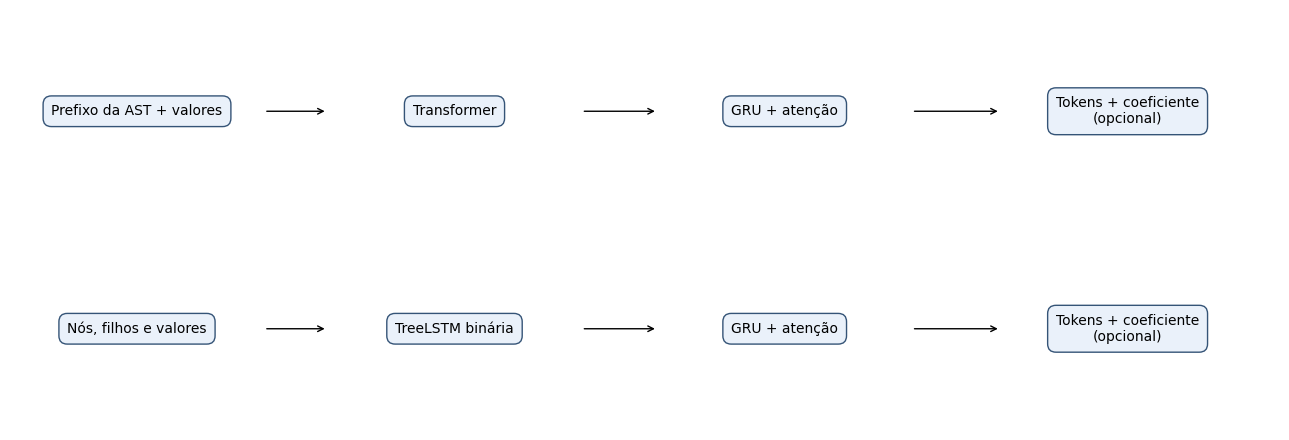

In [2]:
codec_preview=CanonicalCodec()
architecture_rows=[]
with torch.random.fork_rng(devices=[]):
    for variant in EXPERIMENT_CONFIG['variants']:
        torch.manual_seed(EXPERIMENT_CONFIG['training_seed'])
        model=CanonicalEncoderDecoder(codec_preview.vocab_size,variant['encoder'],variant['coefficients'],
                                      **EXPERIMENT_CONFIG['model'])
        architecture_rows.append({'Variante':variant['name'],
                                 'Parâmetros treináveis':sum(p.numel() for p in model.parameters())})
display(pd.DataFrame(architecture_rows))
fig,axes=plt.subplots(2,1,figsize=(13,4.5))
for ax,encoder,source in zip(axes,['Transformer','TreeLSTM binária'],['Prefixo da AST + valores','Nós, filhos e valores']):
    ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
    blocks=[(0.1,source),(0.35,encoder),(0.61,'GRU + atenção'),(0.88,'Tokens + coeficiente'+chr(10)+'(opcional)')]
    for x,label in blocks:
        ax.text(x,.5,label,ha='center',va='center',fontsize=10,
                bbox=dict(boxstyle='round,pad=.6',facecolor='#eaf1fa',edgecolor='#355477'))
    for left,right in zip(blocks[:-1],blocks[1:]):
        ax.annotate('',xy=(right[0]-.10,.5),xytext=(left[0]+.10,.5),arrowprops={'arrowstyle':'->'})
fig.tight_layout();plt.show()

**O que foi feito:** mostramos a quantidade de parâmetros e o caminho dos dados em cada arquitetura. As duas tarefas compartilham o mesmo encoder e decoder base; a variante conjunta acrescenta uma cabeça numérica.

## 2. Dataset, alvos e divisão sem compartilhamento de skeletons

O sorteador combinatório amostra ASTs com reposição. O canonizador exato gera o skeleton realizado e seus coeficientes. Um hash estável do skeleton e da seed de divisão escolhe treino, validação ou teste com faixas de 80%, 10% e 10%; a geração continua até preencher as cotas. ASTs diferentes que resultam no mesmo skeleton permanecem juntas. Essa divisão mede a composição de skeletons novos, preservando a identidade de séries e lags.

A sequência de saída começa com `BOS`, escreve os fatores de cada termo, fecha o termo com `END_TERM` e termina com `EOS`. Um `END_TERM` sem fatores representa a constante. Exemplo:

```text
Fórmula:       6 + 3*x0[t-1] + 2*x1[t-2] + x0[t-1]*x1[t-2]
Tokens:        BOS END_TERM LAG(0,1) END_TERM LAG(1,2) END_TERM
               LAG(0,1) LAG(1,2) END_TERM EOS
Coeficientes:      6                   3                   2
                                          1 (no último END_TERM)
```

O exemplo ilustra a codificação multivariada suportada pelo código. O treino atual usa somente a série 0. Ambos os objetivos recebem os valores numéricos da AST, porque cancelamentos numéricos podem alterar o skeleton realizado.

In [3]:
datasets,dataset_summary,codec=prepare_dataset(EXPERIMENT_CONFIG,RUN_DIR)
print(dataset_summary)
example_rows=[]
for e in datasets['train'][:8]:
    source_tokens=[{1:'ADD',2:'MUL',3:'PARAM'}.get(t,f'LAG{codec.token_atom(t)}' if t>=4 else 'PAD')
                   for t in e['prefix_ids']]
    example_rows.append({'AST sorteada':e['formula'],
                        'Skeleton alvo':format_prediction(e['skeleton']),
                        'Coeficientes':e['coefficients'],
                        'Tokens da entrada':' '.join(source_tokens),
                        'Valores alinhados à entrada':e['prefix_values'],
                        'Tokens do alvo':codec.target_text(e['target'])})
display(pd.DataFrame(example_rows))
data_rows=[]
for name,examples in datasets.items():
    coefficients=np.asarray([value for e in examples for value in e['coefficients']])
    data_rows.append({'Partição':name,'Exemplos':len(examples),
        'Skeletons distintos':dataset_summary['distinct_skeletons'][name],
        'Média de termos':np.mean([len(e['skeleton']) for e in examples]),
        'Coeficientes iguais a 1 (%)':100*np.mean(coefficients==1),
        'MAE ao sempre prever coeficiente 1':np.mean(np.abs(coefficients-1))})
display(pd.DataFrame(data_rows).round(4))

{'attempts': 50021, 'sizes': {'train': 40000, 'validation': 4000, 'test': 4000}, 'distinct_skeletons': {'train': 39691, 'validation': 3979, 'test': 3981}, 'fingerprint': '3e12d7aaf861844f4ca8f4915a9fe84eddf719b04cffeacf177fb5d20528ef42', 'split_intersections': 0, 'max_source_nodes': 13, 'max_target_steps': 49}


,AST sorteada,Skeleton alvo,Coeficientes,Tokens da entrada,Valores alinhados à entrada,Tokens do alvo
0,((x_0(t-3) + (x_0(t-11) + x_0(t-9))) + ((x_0(t-5) * (x_0(t-5) * 0.758258)) * x_0(t-2))),s_0[t-3] + s_0[t-9] + s_0[t-11] + s_0[t-2] * s_0[t-5] * s_0[t-5],"(1.0, 1.0, 1.0, 0.7582580391566761)","ADD ADD LAG(0, 3) ADD LAG(0, 11) LAG(0, 9) MUL MUL LAG(0, 5) MUL LAG(0, 5) PARAM LAG(0, 2)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.7582580391566761, 0.0]","BOS LAG(0, 3) END_TERM LAG(0, 9) END_TERM LAG(0, 11) END_TERM LAG(0, 2) LAG(0, 5) LAG(0, 5) END_TERM EOS"
1,(x_0(t-4) + ((x_0(t-1) * x_0(t-1)) + (((x_0(t-6) * x_0(t-9)) + x_0(t-5)) + x_0(t-1)))),s_0[t-1] + s_0[t-4] + s_0[t-5] + s_0[t-1] * s_0[t-1] + s_0[t-6] * s_0[t-9],"(1.0, 1.0, 1.0, 1.0, 1.0)","ADD LAG(0, 4) ADD MUL LAG(0, 1) LAG(0, 1) ADD ADD MUL LAG(0, 6) LAG(0, 9) LAG(0, 5) LAG(0, 1)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 1) END_TERM LAG(0, 4) END_TERM LAG(0, 5) END_TERM LAG(0, 1) LAG(0, 1) END_TERM LAG(0, 6) LAG(0, 9) END_TERM EOS"
2,((x_0(t-12) * -0.14621) + ((x_0(t-1) + ((x_0(t-10) * x_0(t-3)) * x_0(t-10))) * x_0(t-5))),s_0[t-12] + s_0[t-1] * s_0[t-5] + s_0[t-3] * s_0[t-5] * s_0[t-10] * s_0[t-10],"(-0.14620958265675094, 1.0, 1.0)","ADD MUL LAG(0, 12) PARAM MUL ADD LAG(0, 1) MUL MUL LAG(0, 10) LAG(0, 3) LAG(0, 10) LAG(0, 5)","[0.0, 0.0, 0.0, -0.14620958265675094, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 12) END_TERM LAG(0, 1) LAG(0, 5) END_TERM LAG(0, 3) LAG(0, 5) LAG(0, 10) LAG(0, 10) END_TERM EOS"
3,((x_0(t-12) + x_0(t-9)) + (-0.386313 + (((x_0(t-3) + x_0(t-2)) + x_0(t-9)) * x_0(t-6)))),1 + s_0[t-9] + s_0[t-12] + s_0[t-2] * s_0[t-6] + s_0[t-3] * s_0[t-6] + s_0[t-6] * s_0[t-9],"(-0.38631302827534575, 1.0, 1.0, 1.0, 1.0, 1.0)","ADD ADD LAG(0, 12) LAG(0, 9) ADD PARAM MUL ADD ADD LAG(0, 3) LAG(0, 2) LAG(0, 9) LAG(0, 6)","[0.0, 0.0, 0.0, 0.0, 0.0, -0.38631302827534575, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS END_TERM LAG(0, 9) END_TERM LAG(0, 12) END_TERM LAG(0, 2) LAG(0, 6) END_TERM LAG(0, 3) LAG(0, 6) END_TERM LAG(0, 6) LAG(0, 9) END_TERM EOS"
4,(x_0(t-8) * (((x_0(t-5) + ((x_0(t-5) * x_0(t-9)) + x_0(t-10))) * x_0(t-6)) + x_0(t-2))),s_0[t-2] * s_0[t-8] + s_0[t-5] * s_0[t-6] * s_0[t-8] + s_0[t-6] * s_0[t-8] * s_0[t-10] + s_0[t-5] * s_0[t-6] * s_0[t-8] * s_0[t-9],"(1.0, 1.0, 1.0, 1.0)","MUL LAG(0, 8) ADD MUL ADD LAG(0, 5) ADD MUL LAG(0, 5) LAG(0, 9) LAG(0, 10) LAG(0, 6) LAG(0, 2)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 2) LAG(0, 8) END_TERM LAG(0, 5) LAG(0, 6) LAG(0, 8) END_TERM LAG(0, 6) LAG(0, 8) LAG(0, 10) END_TERM LAG(0, 5) LAG(0, 6) LAG(0, 8) LAG(0, 9) END_TERM EOS"
5,(x_0(t-10) + (((x_0(t-3) * (x_0(t-5) + x_0(t-6))) + x_0(t-11)) + (x_0(t-8) + x_0(t-11)))),s_0[t-8] + s_0[t-10] + s_0[t-11] + s_0[t-3] * s_0[t-5] + s_0[t-3] * s_0[t-6],"(1.0, 1.0, 2.0, 1.0, 1.0)","ADD LAG(0, 10) ADD ADD MUL LAG(0, 3) ADD LAG(0, 5) LAG(0, 6) LAG(0, 11) ADD LAG(0, 8) LAG(0, 11)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 8) END_TERM LAG(0, 10) END_TERM LAG(0, 11) END_TERM LAG(0, 3) LAG(0, 5) END_TERM LAG(0, 3) LAG(0, 6) END_TERM EOS"
6,((x_0(t-5) * (x_0(t-3) + (x_0(t-3) + x_0(t-2)))) * ((x_0(t-2) + x_0(t-9)) * x_0(t-3))),s_0[t-2] * s_0[t-2] * s_0[t-3] * s_0[t-5] + s_0[t-2] * s_0[t-3] * s_0[t-3] * s_0[t-5] + s_0[t-2] * s_0[t-3] * s_0[t-5] * s_0[t-9] + s_0[t-3] * s_0[t-3] * s_0[t-5] * s_0[t-9],"(1.0, 2.0, 1.0, 2.0)","MUL MUL LAG(0, 5) ADD LAG(0, 3) ADD LAG(0, 3) LAG(0, 2) MUL ADD LAG(0, 2) LAG(0, 9) LAG(0, 3)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 2) LAG(0, 2) LAG(0, 3) LAG(0, 5) END_TERM LAG(0, 2) LAG(0, 3) LAG(0, 3) LAG(0, 5) END_TERM LAG(0, 2) LAG(0, 3) LAG(0, 5) LAG(0, 9) END_TERM LAG(0, 3) LAG(0, 3) LAG(0, 5) LAG(0, 9) END_TERM EOS"
7,(x_0(t-10) + ((x_0(t-12) * (x_0(t-8) * x_0(t-8))) + ((x_0(t-9) * x_0(t-8)) + x_0(t-9)))),s_0[t-9] + s_0[t-10] + s_0[t-8] * s_0[t-9] + s_0[t-8] * s_0[t-8] * s_0[t-12],

,Partição,Exemplos,Skeletons distintos,Média de termos,Coeficientes iguais a 1 (%),MAE ao sempre prever coeficiente 1
0,train,40000,39691,4.4938,74.1380,0.2614
1,validation,4000,3979,4.4642,73.8366,0.2614
2,test,4000,3981,4.4895,73.9615,0.2599


**O que foi feito:** geramos ou carregamos o dataset reproduzível, verificamos as interseções vazias entre skeletons e mostramos exemplos reais. O baseline de coeficiente um contextualiza a frequência de coeficientes implícitos do gerador.

## 3. Treinamento e métricas

Durante o treino usamos *teacher forcing*: o decoder recebe os tokens anteriores corretos, com perda de entropia cruzada sobre o próximo token. Para a tarefa conjunta, somamos uma perda Huber entre o valor previsto e `asinh(coeficiente)` apenas nas posições `END_TERM`. A previsão volta à escala original por `sinh`. Essa transformação preserva o sinal e reduz a escala dos valores maiores.

O melhor checkpoint é escolhido pela perda de validação. Há redução da taxa de aprendizado quando ela deixa de melhorar e parada antecipada após oito épocas sem melhora, respeitando pelo menos dez épocas. O teste é avaliado ao final de cada variante, usando o checkpoint selecionado pela validação.

| Métrica | Cálculo e interpretação |
|---|---|
| Skeleton exato | Fração de gerações válidas cuja lista ordenada de monômios coincide com o alvo. |
| F1 dos termos | F1 micro entre os conjuntos de monômios previstos e verdadeiros, somando TP, FP e FN. |
| Validade | Presença de EOS, fechamento dos termos, grau até quatro, fatores e termos ordenados e sem termos duplicados. |
| RMSE dos coeficientes na união | Erro sobre a união dos monômios previstos e verdadeiros; monômios ausentes recebem zero. Uma expressão inválida é tratada como mapa vazio para esta métrica. |
| MAE dos coeficientes correspondentes | Erro apenas nos monômios presentes nos dois mapas válidos; mostramos também a quantidade de correspondências. |
| Expressão conjunta correta | Skeleton exato e todos os coeficientes dentro de tolerância absoluta 0,01 e relativa 0,01. |

As métricas principais usam geração autoregressiva **somente a partir da AST**, iniciada por `BOS`, sem fornecer tokens do alvo. O limite é 64 passos, e `PAD`/`BOS` são bloqueados como próximos tokens. A ordenação e o fechamento dos termos são aprendidos; a avaliação registra saídas inválidas. As métricas com prefixos corretos são identificadas como *teacher forcing* e ficam separadas da geração livre.

Código: `canonical_data.py`, `canonical_models.py` e `canonical_training.py` em `src/tsfmxai/symbolic_regression/`. Os testes verificam codificação, isolamento de splits, causalidade do decoder, independência dos alvos na geração, métricas e uma execução curta com checkpoints.

## 4. Treino: `transformer_skeleton`

A célula imprime o progresso por época. Os checkpoints `best.pt` e `last.pt` permitem avaliar o melhor modelo e retomar da última época concluída.

In [4]:
result_0=train_variant(EXPERIMENT_CONFIG['variants'][0],EXPERIMENT_CONFIG,
                          datasets,codec,RUN_DIR)
display(pd.DataFrame(result_0['history']))
print('Melhor época:',result_0['best_epoch'])
print('Teste em geração livre:',result_0['test'])

transformer_skeleton: epoch 1/40 train=1.2810 val=0.8220 greedy_exact=0.008


transformer_skeleton: epoch 2/40 train=0.7685 val=0.6406 greedy_exact=0.031


transformer_skeleton: epoch 3/40 train=0.6539 val=0.5513 greedy_exact=0.090


transformer_skeleton: epoch 4/40 train=0.5791 val=0.4824 greedy_exact=0.113


transformer_skeleton: epoch 5/40 train=0.5245 val=0.4330 greedy_exact=0.148


transformer_skeleton: epoch 6/40 train=0.4799 val=0.3963 greedy_exact=0.178


... (32 outputs left out)

transformer_skeleton: epoch 39/40 train=0.1040 val=0.0720 greedy_exact=0.762


transformer_skeleton: epoch 40/40 train=0.1025 val=0.0696 greedy_exact=0.779


,epoch,train_loss,validation_loss,validation_token_accuracy,validation_greedy_exact,validation_greedy_f1,learning_rate
0,1,1.280964,0.821977,0.695793,0.007812,0.411006,0.0005
1,2,0.768549,0.640609,0.760046,0.031250,0.510086,0.0005
2,3,0.653904,0.551267,0.795183,0.089844,0.565919,0.0005
3,4,0.579108,0.482435,0.819576,0.113281,0.601674,0.0005
4,5,0.524532,0.432976,0.839749,0.148438,0.643946,0.0005
5,6,0.479909,0.396300,0.855103,0.177734,0.671954,0.0005
6,7,0.442287,0.358014,0.867599,0.220703,0.705960,0.0005
7,8,0.408367,0.320994,0.882774,0.246094,0.722641,0.0005
8,9,0.379652,0.293796,0.892512,0.289062,0.748946,0.0005
9,10,0.350108,0.262157,0.906599,0.326172,0.776742,0.0005


Melhor época: 40
Teste em geração livre: {'count': 4000, 'skeleton_exact': 0.7435, 'valid_rate': 0.90675, 'term_precision': 0.9482651622002821, 'term_recall': 0.9359616883840072, 'term_f1': 0.942073256172407, 'joint_exact': None, 'coefficient_union_rmse': None, 'coefficient_matched_mae': None, 'matched_coefficient_count': 0, 'seconds': 2.7421866999939084}


**O que foi feito:** treinamos a variante `transformer_skeleton` e avaliamos seu melhor checkpoint no teste. Ao reexecutar uma variante concluída com a mesma configuração, seus resultados salvos são carregados.

## 5. Treino: `transformer_joint`

A célula imprime o progresso por época. Os checkpoints `best.pt` e `last.pt` permitem avaliar o melhor modelo e retomar da última época concluída.

In [5]:
result_1=train_variant(EXPERIMENT_CONFIG['variants'][1],EXPERIMENT_CONFIG,
                          datasets,codec,RUN_DIR)
display(pd.DataFrame(result_1['history']))
print('Melhor época:',result_1['best_epoch'])
print('Teste em geração livre:',result_1['test'])

transformer_joint: epoch 1/40 train=1.4043 val=0.8791 greedy_exact=0.008


transformer_joint: epoch 2/40 train=0.8226 val=0.6819 greedy_exact=0.068


transformer_joint: epoch 3/40 train=0.6947 val=0.5867 greedy_exact=0.094


transformer_joint: epoch 4/40 train=0.6144 val=0.5106 greedy_exact=0.121


transformer_joint: epoch 5/40 train=0.5546 val=0.4536 greedy_exact=0.174


transformer_joint: epoch 6/40 train=0.5089 val=0.4136 greedy_exact=0.197


... (32 outputs left out)

transformer_joint: epoch 39/40 train=0.1328 val=0.1002 greedy_exact=0.771


transformer_joint: epoch 40/40 train=0.1301 val=0.0945 greedy_exact=0.777


,epoch,train_loss,validation_loss,validation_token_accuracy,validation_greedy_exact,validation_greedy_f1,learning_rate
0,1,1.404281,0.879109,0.697676,0.007812,0.408352,0.0005
1,2,0.822586,0.681886,0.764655,0.068359,0.528957,0.0005
2,3,0.694732,0.586750,0.798267,0.093750,0.582090,0.0005
3,4,0.614412,0.510615,0.825906,0.121094,0.618026,0.0005
4,5,0.554615,0.453612,0.846582,0.173828,0.659808,0.0005
5,6,0.508907,0.413600,0.862568,0.197266,0.686283,0.0005
6,7,0.471475,0.391967,0.871170,0.212891,0.712095,0.0005
7,8,0.439710,0.350222,0.886588,0.271484,0.740659,0.0005
8,9,0.411083,0.326531,0.894232,0.287109,0.746977,0.0005
9,10,0.388235,0.296957,0.906307,0.316406,0.762494,0.0005


Melhor época: 40
Teste em geração livre: {'count': 4000, 'skeleton_exact': 0.73075, 'valid_rate': 0.88525, 'term_precision': 0.9475161380858826, 'term_recall': 0.9399710435460519, 'term_f1': 0.943728510329019, 'joint_exact': 0.00025, 'coefficient_union_rmse': 0.5309099581869858, 'coefficient_matched_mae': 0.14941095718505423, 'matched_coefficient_count': 14931, 'seconds': 2.921277199871838}


**O que foi feito:** treinamos a variante `transformer_joint` e avaliamos seu melhor checkpoint no teste. Ao reexecutar uma variante concluída com a mesma configuração, seus resultados salvos são carregados.

## 6. Treino: `tree_lstm_skeleton`

A célula imprime o progresso por época. Os checkpoints `best.pt` e `last.pt` permitem avaliar o melhor modelo e retomar da última época concluída.

In [6]:
result_2=train_variant(EXPERIMENT_CONFIG['variants'][2],EXPERIMENT_CONFIG,
                          datasets,codec,RUN_DIR)
display(pd.DataFrame(result_2['history']))
print('Melhor época:',result_2['best_epoch'])
print('Teste em geração livre:',result_2['test'])

tree_lstm_skeleton: epoch 1/40 train=1.1366 val=0.6507 greedy_exact=0.033


tree_lstm_skeleton: epoch 2/40 train=0.5628 val=0.4813 greedy_exact=0.111


tree_lstm_skeleton: epoch 3/40 train=0.4380 val=0.3920 greedy_exact=0.205


tree_lstm_skeleton: epoch 4/40 train=0.3671 val=0.3378 greedy_exact=0.244


tree_lstm_skeleton: epoch 5/40 train=0.3141 val=0.2887 greedy_exact=0.346


tree_lstm_skeleton: epoch 6/40 train=0.2745 val=0.2672 greedy_exact=0.373


... (32 outputs left out)

tree_lstm_skeleton: epoch 39/40 train=0.0430 val=0.0956 greedy_exact=0.752


tree_lstm_skeleton: epoch 40/40 train=0.0425 val=0.0991 greedy_exact=0.750


,epoch,train_loss,validation_loss,validation_token_accuracy,validation_greedy_exact,validation_greedy_f1,learning_rate
0,1,1.136580,0.650724,0.772786,0.033203,0.525305,0.0005
1,2,0.562811,0.481281,0.825760,0.111328,0.635659,0.0005
2,3,0.437954,0.391997,0.862000,0.205078,0.693091,0.0005
3,4,0.367116,0.337843,0.878197,0.244141,0.723128,0.0005
4,5,0.314059,0.288652,0.896650,0.345703,0.763410,0.0005
5,6,0.274545,0.267229,0.905658,0.373047,0.782513,0.0005
6,7,0.243359,0.235940,0.914600,0.443359,0.807266,0.0005
7,8,0.218685,0.211703,0.924776,0.478516,0.824074,0.0005
8,9,0.198523,0.198650,0.929629,0.484375,0.823374,0.0005
9,10,0.180646,0.187085,0.932209,0.521484,0.851008,0.0005


Melhor época: 39
Teste em geração livre: {'count': 4000, 'skeleton_exact': 0.71925, 'valid_rate': 0.89075, 'term_precision': 0.9236020251436373, 'term_recall': 0.9041095890410958, 'term_f1': 0.9137518642541577, 'joint_exact': None, 'coefficient_union_rmse': None, 'coefficient_matched_mae': None, 'matched_coefficient_count': 0, 'seconds': 2.5758146999869496}


**O que foi feito:** treinamos a variante `tree_lstm_skeleton` e avaliamos seu melhor checkpoint no teste. Ao reexecutar uma variante concluída com a mesma configuração, seus resultados salvos são carregados.

## 7. Treino: `tree_lstm_joint`

A célula imprime o progresso por época. Os checkpoints `best.pt` e `last.pt` permitem avaliar o melhor modelo e retomar da última época concluída.

In [7]:
result_3=train_variant(EXPERIMENT_CONFIG['variants'][3],EXPERIMENT_CONFIG,
                          datasets,codec,RUN_DIR)
display(pd.DataFrame(result_3['history']))
print('Melhor época:',result_3['best_epoch'])
print('Teste em geração livre:',result_3['test'])

tree_lstm_joint: epoch 1/40 train=1.2488 val=0.7168 greedy_exact=0.029


tree_lstm_joint: epoch 2/40 train=0.6275 val=0.5346 greedy_exact=0.092


tree_lstm_joint: epoch 3/40 train=0.4961 val=0.4450 greedy_exact=0.188


tree_lstm_joint: epoch 4/40 train=0.4161 val=0.3888 greedy_exact=0.246


tree_lstm_joint: epoch 5/40 train=0.3601 val=0.3355 greedy_exact=0.330


tree_lstm_joint: epoch 6/40 train=0.3186 val=0.2997 greedy_exact=0.373


... (32 outputs left out)

tree_lstm_joint: epoch 39/40 train=0.0654 val=0.1194 greedy_exact=0.742


tree_lstm_joint: epoch 40/40 train=0.0645 val=0.1192 greedy_exact=0.691


,epoch,train_loss,validation_loss,validation_token_accuracy,validation_greedy_exact,validation_greedy_f1,learning_rate
0,1,1.248789,0.716806,0.767788,0.029297,0.527410,0.0005
1,2,0.627503,0.534605,0.823358,0.091797,0.614123,0.0005
2,3,0.496141,0.444960,0.855167,0.187500,0.688086,0.0005
3,4,0.416106,0.388802,0.873994,0.246094,0.717049,0.0005
4,5,0.360078,0.335509,0.893096,0.330078,0.758161,0.0005
5,6,0.318568,0.299731,0.906631,0.373047,0.779676,0.0005
6,7,0.287083,0.280247,0.913691,0.425781,0.806417,0.0005
7,8,0.260971,0.256042,0.921806,0.476562,0.826649,0.0005
8,9,0.239883,0.232598,0.929401,0.478516,0.818680,0.0005
9,10,0.220354,0.227129,0.930456,0.484375,0.834208,0.0005


Melhor época: 38
Teste em geração livre: {'count': 4000, 'skeleton_exact': 0.71875, 'valid_rate': 0.8945, 'term_precision': 0.9213284721431013, 'term_recall': 0.9006014032743067, 'term_f1': 0.9108470376210859, 'joint_exact': 0.0005, 'coefficient_union_rmse': 0.5465286123908437, 'coefficient_matched_mae': 0.17094920886002077, 'matched_coefficient_count': 14467, 'seconds': 2.663347400026396}


**O que foi feito:** treinamos a variante `tree_lstm_joint` e avaliamos seu melhor checkpoint no teste. Ao reexecutar uma variante concluída com a mesma configuração, seus resultados salvos são carregados.

## 8. Comparação final e análise dos erros

As tabelas e curvas abaixo são preenchidas após os quatro treinamentos. A comparação corresponde a uma seed de treino por variante. Os exemplos mostram até seis acertos e seis falhas encontrados na ordem do teste; as métricas usam todo o conjunto de teste.

,Modelo,Parâmetros,Melhor época,Épocas executadas,Skeleton exato (%),F1 termos,Validade (%),Expressão conjunta correta (%),RMSE coeficientes união,MAE coeficientes correspondentes,Coeficientes correspondentes,Tempo treino e avaliação (min),Tempo geração livre teste (s)
0,transformer_skeleton,285712,40,40,74.350,0.9421,90.675,NaN,NaN,NaN,0,34.5977,2.7422
1,transformer_joint,285809,40,40,73.075,0.9437,88.525,0.025,0.5309,0.1494,14931,35.6886,2.9213
2,tree_lstm_skeleton,236560,39,40,71.925,0.9138,89.075,NaN,NaN,NaN,0,27.9850,2.5758
3,tree_lstm_joint,236657,38,40,71.875,0.9108,89.450,0.050,0.5465,0.1709,14467,29.1714,2.6633


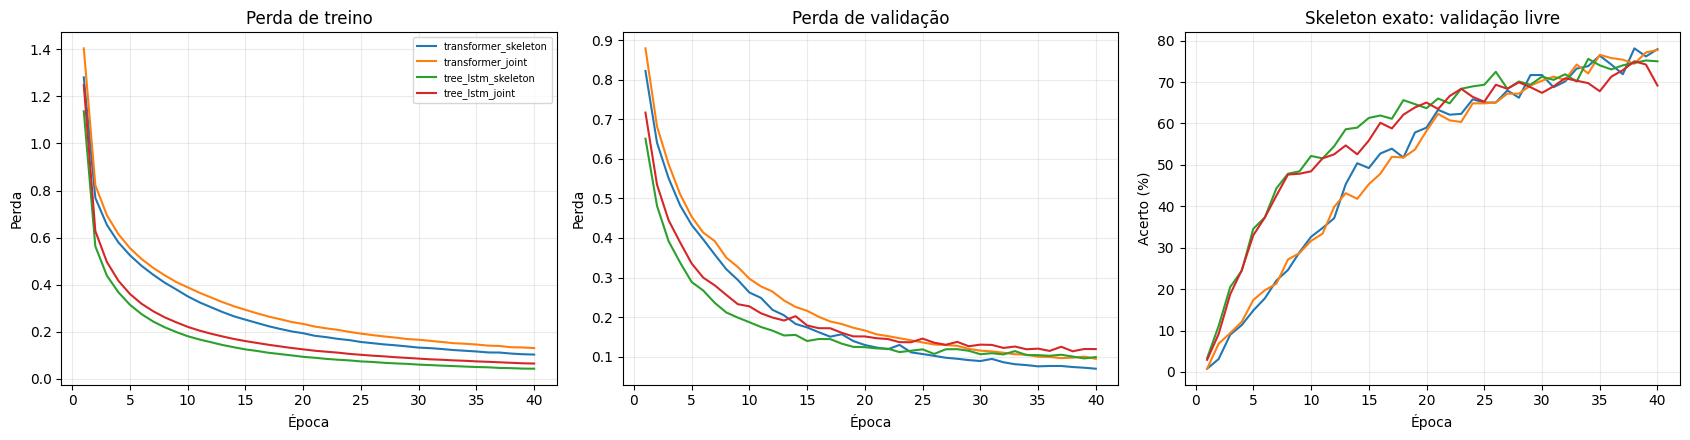

transformer_skeleton


,input_formula,target,predicted,valid,skeleton_exact,joint_exact
0,((x_0(t-11) + (((x_0(t-8) * x_0(t-12)) + x_0(t-12)) * x_0(t-1))) * (0.425209 + x_0(t-1))),s_0[t-11] + s_0[t-1] * s_0[t-11] + s_0[t-1] * s_0[t-12] + s_0[t-1] * s_0[t-1] * s_0[t-12] + s_0[t-1] * s_0[t-8] * s_0[t-12] + s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],s_0[t-1] + s_0[t-11] + s_0[t-1] * s_0[t-12] + s_0[t-1] * s_0[t-1] * s_0[t-12] + s_0[t-1] * s_0[t-8] * s_0[t-12] + s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],True,False,None
1,((x_0(t-11) * ((x_0(t-7) + (x_0(t-5) * x_0(t-12))) + (x_0(t-8) + x_0(t-7)))) * x_0(t-4)),s_0[t-4] * s_0[t-7] * s_0[t-11] + s_0[t-4] * s_0[t-8] * s_0[t-11] + s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],s_0[t-4] * s_0[t-7] * s_0[t-11] + s_0[t-4] * s_0[t-8] * s_0[t-11] + s_0[t-4] * s_0[t-7] * s_0[t-11] * s_0[t-12],True,False,None
2,((x_0(t-6) * x_0(t-2)) + (x_0(t-6) * (x_0(t-4) + ((x_0(t-1) * x_0(t-10)) * -0.427521)))),s_0[t-2] * s_0[t-6] + s_0[t-4] * s_0[t-6] + s_0[t-1] * s_0[t-6] * s_0[t-10],s_0[t-2] * s_0[t-6] + s_0[t-4] * s_0[t-6] + s_0[t-1] * s_0[t-6] * s_0[t-10],True,True,None
3,((x_0(t-8) + (x_0(t-7) * x_0(t-7))) + ((x_0(t-10) + x_0(t-5)) * (x_0(t-6) * x_0(t-5)))),s_0[t-8] + s_0[t-7] * s_0[t-7] + s_0[t-5] * s_0[t-5] * s_0[t-6] + s_0[t-5] * s_0[t-6] * s_0[t-10],s_0[t-8] + s_0[t-5] * s_0[t-6] + s_0[t-7] * s_0[t-7] + s_0[t-5] * s_0[t-5] * s_0[t-6],True,False,None
4,(x_0(t-7) * (x_0(t-6) * (-0.866491 + ((x_0(t-1) + (x_0(t-7) + x_0(t-2))) + x_0(t-1))))),s_0[t-6] * s_0[t-7] + s_0[t-1] * s_0[t-6] * s_0[t-7] + s_0[t-2] * s_0[t-6] * s_0[t-7] + s_0[t-6] * s_0[t-7] * s_0[t-7],s_0[t-6] * s_0[t-7] + s_0[t-1] * s_0[t-6] * s_0[t-7] + s_0[t-2] * s_0[t-6] * s_0[t-7] + s_0[t-6] * s_0[t-7] * s_0[t-7],True,True,None
5,(0.781478 + (((x_0(t-4) + (x_0(t-3) + x_0(t-1))) + (x_0(t-1) * x_0(t-1))) * x_0(t-2))),1 + s_0[t-1] * s_0[t-2] + s_0[t-2] * s_0[t-3] + s_0[t-2] * s_0[t-4] + s_0[t-1] * s_0[t-1] * s_0[t-2],1 + s_0[t-1] * s_0[t-2] + s_0[t-2] * s_0[t-3] + s_0[t-2] * s_0[t-4] + s_0[t-1] * s_0[t-1] * s_0[t-2],True,True,None
6,((x_0(t-9) + (-0.406079 * x_0(t-9))) + (((x_0(t-11) * x_0(t-2)) + x_0(t-11)) * x_0(t-8))),s_0[t-9] + s_0[t-8] * s_0[t-11] + s_0[t-2] * s_0[t-8] * s_0[t-11],s_0[t-9] + s_0[t-9] + s_0[t-8] * s_0[t-11] + s_0[t-2] * s_0[t-8] * s_0[t-11],False,False,None
7,(x_0(t-7) + (x_0(t-2) * (x_0(t-12) + ((x_0(t-8) + x_0(t-2)) + (x_0(t-10) + x_0(t-12)))))),s_0[t-7] + s_0[t-2] * s_0[t-2] + s_0[t-2] * s_0[t-8] + s_0[t-2] * s_0[t-10] + s_0[t-2] * s_0[t-12],s_0[t-7] + s_0[t-2] * s_0[t-2] + s_0[t-2] * s_0[t-8] + s_0[t-2] * s_0[t-10] + s_0[t-2] * s_0[t-12],True,True,None
8,(((x_0(t-6) + ((x_0(t-2) + (x_0(t-8) * x_0(t-7))) * x_0(t-10))) * x_0(t-1)) + x_0(t-7)),s_0[t-7] + s_0[t-1] * s_0[t-6] + s_0[t-1] * s_0[t-2] * s_0[t-10] + s_0[t-1] * s_0[t-7] * s_0[t-8] * s_0[t-10],s_0[t-7] + s_0[t-1] * s_0[t-6] + s_0[t-1] * s_0[t-2] * s_0[t-10] + s_0[t-1] * s_0[t-7] * s_0[t-8] * s_0[t-10],True,True,None
9,((x_0(t-3) + (x_0(t-10) * 0.690588)) + (x_0(t-7) + (x_0(t-12) * (x_0(t-10) * x_0(t-10))))),s_0[t-3] + s_0[t-7] + s_0[t-10] + s_0[t-10] * s_0[t-10] * s_0[t-12],s_0[t-3] + s_0[t-7] + s_0[t-10] + s_0[t-10] * s_0[t-10] * s_0[t-12],True,True,None


,group,value,count,skeleton_exact
0,operator_count,5,45,0.7778
1,operator_count,6,3955,0.7431
2,degree,1,134,0.9701
3,degree,2,981,0.7635
4,degree,3,1453,0.7261
5,degree,4,1432,0.7263
6,parameter_count,0,2096,0.7362
7,parameter_count,1,1431,0.7582
8,parameter_count,2,404,0.7228
9,parameter_count,3,63,0.7778


transformer_joint


,input_formula,target,predicted,valid,skeleton_exact,joint_exact
0,((x_0(t-11) + (((x_0(t-8) * x_0(t-12)) + x_0(t-12)) * x_0(t-1))) * (0.425209 + x_0(t-1))),(0.4252)*s_0[t-11] + (1)*s_0[t-1] * s_0[t-11] + (0.4252)*s_0[t-1] * s_0[t-12] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-12] + (0.4252)*s_0[t-1] * s_0[t-8] * s_0[t-12] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],(0.4961)*s_0[t-11] + (0.7819)*s_0[t-1] * s_0[t-12] + (1.038)*s_0[t-1] * s_0[t-1] * s_0[t-12] + (0.9581)*s_0[t-1] * s_0[t-8] * s_0[t-12] + (1.061)*s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],True,False,False
1,((x_0(t-11) * ((x_0(t-7) + (x_0(t-5) * x_0(t-12))) + (x_0(t-8) + x_0(t-7)))) * x_0(t-4)),(2)*s_0[t-4] * s_0[t-7] * s_0[t-11] + (1)*s_0[t-4] * s_0[t-8] * s_0[t-11] + (1)*s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],(1.134)*s_0[t-4] * s_0[t-7] * s_0[t-11] + (1.093)*s_0[t-4] * s_0[t-8] * s_0[t-11] + (1.049)*s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],True,True,False
2,((x_0(t-6) * x_0(t-2)) + (x_0(t-6) * (x_0(t-4) + ((x_0(t-1) * x_0(t-10)) * -0.427521)))),(1)*s_0[t-2] * s_0[t-6] + (1)*s_0[t-4] * s_0[t-6] + (-0.4275)*s_0[t-1] * s_0[t-6] * s_0[t-10],(0.9468)*s_0[t-2] * s_0[t-6] + (0.9216)*s_0[t-4] * s_0[t-6] + (-0.3639)*s_0[t-1] * s_0[t-6] * s_0[t-10],True,True,False
3,((x_0(t-8) + (x_0(t-7) * x_0(t-7))) + ((x_0(t-10) + x_0(t-5)) * (x_0(t-6) * x_0(t-5)))),(1)*s_0[t-8] + (1)*s_0[t-7] * s_0[t-7] + (1)*s_0[t-5] * s_0[t-5] * s_0[t-6] + (1)*s_0[t-5] * s_0[t-6] * s_0[t-10],(0.8523)*s_0[t-8] + (0.8837)*s_0[t-5] * s_0[t-6] + (0.8023)*s_0[t-5] * s_0[t-7] + (0.9716)*s_0[t-5] * s_0[t-6] * s_0[t-6],True,False,False
4,(x_0(t-7) * (x_0(t-6) * (-0.866491 + ((x_0(t-1) + (x_0(t-7) + x_0(t-2))) + x_0(t-1))))),(-0.8665)*s_0[t-6] * s_0[t-7] + (2)*s_0[t-1] * s_0[t-6] * s_0[t-7] + (1)*s_0[t-2] * s_0[t-6] * s_0[t-7] + (1)*s_0[t-6] * s_0[t-7] * s_0[t-7],(-0.6943)*s_0[t-6] * s_0[t-7] + (1.123)*s_0[t-1] * s_0[t-6] * s_0[t-7] + (1.13)*s_0[t-2] * s_0[t-6] * s_0[t-7] + (1.111)*s_0[t-6] * s_0[t-6] * s_0[t-7],True,False,False
5,(0.781478 + (((x_0(t-4) + (x_0(t-3) + x_0(t-1))) + (x_0(t-1) * x_0(t-1))) * x_0(t-2))),(0.7815)*1 + (1)*s_0[t-1] * s_0[t-2] + (1)*s_0[t-2] * s_0[t-3] + (1)*s_0[t-2] * s_0[t-4] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-2],(0.6821)*1 + (1.104)*s_0[t-1] * s_0[t-2] + (1.109)*s_0[t-2] * s_0[t-3] + (1.149)*s_0[t-2] * s_0[t-4] + (1.151)*s_0[t-1] * s_0[t-1] * s_0[t-2],True,True,False
6,((x_0(t-9) + (-0.406079 * x_0(t-9))) + (((x_0(t-11) * x_0(t-2)) + x_0(t-11)) * x_0(t-8))),(0.5939)*s_0[t-9] + (1)*s_0[t-8] * s_0[t-11] + (1)*s_0[t-2] * s_0[t-8] * s_0[t-11],(0.4035)*s_0[t-9] + (0.2788)*s_0[t-8] + (0.6777)*s_0[t-9] * s_0[t-11] + (0.9392)*s_0[t-2] * s_0[t-8] * s_0[t-11],False,False,False
7,(x_0(t-7) + (x_0(t-2) * (x_0(t-12) + ((x_0(t-8) + x_0(t-2)) + (x_0(t-10) + x_0(t-12)))))),(1)*s_0[t-7] + (1)*s_0[t-2] * s_0[t-2] + (1)*s_0[t-2] * s_0[t-8] + (1)*s_0[t-2] * s_0[t-10] + (2)*s_0[t-2] * s_0[t-12],(0.9542)*s_0[t-7] + (0.9757)*s_0[t-2] * s_0[t-2] + (1.056)*s_0[t-2] * s_0[t-8] + (1.148)*s_0[t-2] * s_0[t-10] + (1.137)*s_0[t-2] * s_0[t-12],True,True,False
8,(((x_0(t-6) + ((x_0(t-2) + (x_0(t-8) * x_0(t-7))) * x_0(t-10))) * x_0(t-1)) + x_0(t-7)),(1)*s_0[t-7] + (1)*s_0[t-1] * s_0[t-6] + (1)*s_0[t-1] * s_0[t-2] * s_0[t-10] + (1)*s_0[t-1] * s_0[t-7] * s_0[t-8] * s_0[t-10],(0.9712)*s_0[t-7] + (0.9749)*s_0[t-1] * s_0[t-6] + (1.01)*s_0[t-1] * s_0[t-2] * s_0[t-10] + (1.013)*s_0[t-1] * s_0[t-7] * s_0[t-8] * s_0[t-10],True,True,False
9,((x_0(t-3) + (x_0(t-10) * 0.690588)) + (x_0(t-7) + (x_0(t-12) * (x_0(t-10) * x_0(t-10))))),(1)*s_0[t-3] + (1)*s_0[t-7] + (0.6906)*s_0[t-10] + (1)*s_0[t-10] * s_0[t-10] * s_0[t-12],(1.166)*s_0[t-3] + (1.086)*s_0[t-7] + (0.9091)*s_0[t-10] * s_0[t-10] + (0.9458)*s_0[t-10] * s_0[t-10] * s_0[t-12],True,False,False


,group,value,count,skeleton_exact
0,operator_count,5,45,0.6667
1,operator_count,6,3955,0.7315
2,degree,1,134,0.9701
3,degree,2,981,0.7615
4,degree,3,1453,0.6869
5,degree,4,1432,0.7318
6,parameter_count,0,2096,0.7357
7,parameter_count,1,1431,0.7268
8,parameter_count,2,404,0.7277
9,parameter_count,3,63,0.6825


... (2 outputs left out)

,group,value,count,skeleton_exact
0,operator_count,5,45,0.7333
1,operator_count,6,3955,0.7191
2,degree,1,134,0.9627
3,degree,2,981,0.8359
4,degree,3,1453,0.6745
5,degree,4,1432,0.6620
6,parameter_count,0,2096,0.6813
7,parameter_count,1,1431,0.7456
8,parameter_count,2,404,0.8020
9,parameter_count,3,63,0.8254


tree_lstm_joint


,input_formula,target,predicted,valid,skeleton_exact,joint_exact
0,((x_0(t-11) + (((x_0(t-8) * x_0(t-12)) + x_0(t-12)) * x_0(t-1))) * (0.425209 + x_0(t-1))),(0.4252)*s_0[t-11] + (1)*s_0[t-1] * s_0[t-11] + (0.4252)*s_0[t-1] * s_0[t-12] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-12] + (0.4252)*s_0[t-1] * s_0[t-8] * s_0[t-12] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],(0.5156)*s_0[t-11] + (0.7816)*s_0[t-1] * s_0[t-11] + (0.6887)*s_0[t-1] * s_0[t-12] + (1.009)*s_0[t-1] * s_0[t-8] * s_0[t-12] + (1.231)*s_0[t-1] * s_0[t-1] * s_0[t-12] * s_0[t-12],True,False,False
1,((x_0(t-11) * ((x_0(t-7) + (x_0(t-5) * x_0(t-12))) + (x_0(t-8) + x_0(t-7)))) * x_0(t-4)),(2)*s_0[t-4] * s_0[t-7] * s_0[t-11] + (1)*s_0[t-4] * s_0[t-8] * s_0[t-11] + (1)*s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],(1.205)*s_0[t-4] * s_0[t-7] * s_0[t-11] + (1.247)*s_0[t-4] * s_0[t-8] * s_0[t-11] + (1.197)*s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],True,True,False
2,((x_0(t-6) * x_0(t-2)) + (x_0(t-6) * (x_0(t-4) + ((x_0(t-1) * x_0(t-10)) * -0.427521)))),(1)*s_0[t-2] * s_0[t-6] + (1)*s_0[t-4] * s_0[t-6] + (-0.4275)*s_0[t-1] * s_0[t-6] * s_0[t-10],(1.08)*s_0[t-2] * s_0[t-6] + (0.9985)*s_0[t-4] * s_0[t-6] + (-0.3606)*s_0[t-1] * s_0[t-6] * s_0[t-10],True,True,False
3,((x_0(t-8) + (x_0(t-7) * x_0(t-7))) + ((x_0(t-10) + x_0(t-5)) * (x_0(t-6) * x_0(t-5)))),(1)*s_0[t-8] + (1)*s_0[t-7] * s_0[t-7] + (1)*s_0[t-5] * s_0[t-5] * s_0[t-6] + (1)*s_0[t-5] * s_0[t-6] * s_0[t-10],(1.079)*s_0[t-8] + (0.7544)*s_0[t-5] * s_0[t-6] + (1.1)*s_0[t-5] * s_0[t-6] * s_0[t-7] + (1.182)*s_0[t-5] * s_0[t-6] * s_0[t-10],True,False,False
4,(x_0(t-7) * (x_0(t-6) * (-0.866491 + ((x_0(t-1) + (x_0(t-7) + x_0(t-2))) + x_0(t-1))))),(-0.8665)*s_0[t-6] * s_0[t-7] + (2)*s_0[t-1] * s_0[t-6] * s_0[t-7] + (1)*s_0[t-2] * s_0[t-6] * s_0[t-7] + (1)*s_0[t-6] * s_0[t-7] * s_0[t-7],(-0.6161)*s_0[t-6] * s_0[t-7] + (1.261)*s_0[t-1] * s_0[t-6] * s_0[t-7] + (1.16)*s_0[t-2] * s_0[t-6] * s_0[t-7] + (0.9749)*s_0[t-6] * s_0[t-6] * s_0[t-7],True,False,False
5,(0.781478 + (((x_0(t-4) + (x_0(t-3) + x_0(t-1))) + (x_0(t-1) * x_0(t-1))) * x_0(t-2))),(0.7815)*1 + (1)*s_0[t-1] * s_0[t-2] + (1)*s_0[t-2] * s_0[t-3] + (1)*s_0[t-2] * s_0[t-4] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-2],(0.7545)*1 + (1.146)*s_0[t-1] * s_0[t-2] + (1.072)*s_0[t-2] * s_0[t-3] + (1.011)*s_0[t-1] * s_0[t-2] * s_0[t-4] + (0.9983)*s_0[t-1] * s_0[t-2] * s_0[t-3],False,False,False
6,((x_0(t-9) + (-0.406079 * x_0(t-9))) + (((x_0(t-11) * x_0(t-2)) + x_0(t-11)) * x_0(t-8))),(0.5939)*s_0[t-9] + (1)*s_0[t-8] * s_0[t-11] + (1)*s_0[t-2] * s_0[t-8] * s_0[t-11],(1.049)*s_0[t-9] + (0.8803)*s_0[t-8] * s_0[t-11] + (0.8808)*s_0[t-2] * s_0[t-8] * s_0[t-11],True,True,False
7,(x_0(t-7) + (x_0(t-2) * (x_0(t-12) + ((x_0(t-8) + x_0(t-2)) + (x_0(t-10) + x_0(t-12)))))),(1)*s_0[t-7] + (1)*s_0[t-2] * s_0[t-2] + (1)*s_0[t-2] * s_0[t-8] + (1)*s_0[t-2] * s_0[t-10] + (2)*s_0[t-2] * s_0[t-12],(1.098)*s_0[t-7] + (1.036)*s_0[t-2] * s_0[t-2] + (1.282)*s_0[t-2] * s_0[t-8] + (1.237)*s_0[t-2] * s_0[t-10] + (1.213)*s_0[t-2] * s_0[t-12],True,True,False
8,(((x_0(t-6) + ((x_0(t-2) + (x_0(t-8) * x_0(t-7))) * x_0(t-10))) * x_0(t-1)) + x_0(t-7)),(1)*s_0[t-7] + (1)*s_0[t-1] * s_0[t-6] + (1)*s_0[t-1] * s_0[t-2] * s_0[t-10] + (1)*s_0[t-1] * s_0[t-7] * s_0[t-8] * s_0[t-10],(0.8398)*s_0[t-7] + (0.9328)*s_0[t-1] * s_0[t-6] + (0.9581)*s_0[t-1] * s_0[t-2] * s_0[t-10] + (1.106)*s_0[t-1] * s_0[t-7] * s_0[t-8] * s_0[t-10],True,True,False
9,((x_0(t-3) + (x_0(t-10) * 0.690588)) + (x_0(t-7) + (x_0(t-12) * (x_0(t-10) * x_0(t-10))))),(1)*s_0[t-3] + (1)*s_0[t-7] + (0.6906)*s_0[t-10] + (1)*s_0[t-10] * s_0[t-10] * s_0[t-12],(1.132)*s_0[t-3] + (1.175)*s_0[t-7] + (0.5701)*s_0[t-10] + (1.117)*s_0[t-10] * s_0[t-10] * s_0[t-12],True,True,False


,group,value,count,skeleton_exact
0,operator_count,5,45,0.7333
1,operator_count,6,3955,0.7186
2,degree,1,134,0.9478
3,degree,2,981,0.7992
4,degree,3,1453,0.6924
5,degree,4,1432,0.6690
6,parameter_count,0,2096,0.6880
7,parameter_count,1,1431,0.7338
8,parameter_count,2,404,0.7970
9,parameter_count,3,63,0.8730


In [8]:
final_status=finish_study(EXPERIMENT_CONFIG,RUN_DIR)
results=final_status['variants']
summary_rows=[]
for name,result in results.items():
    metrics=result['test']
    summary_rows.append({'Modelo':name,'Parâmetros':result['parameters'],
        'Melhor época':result['best_epoch'],'Épocas executadas':len(result['history']),
        'Skeleton exato (%)':100*metrics['skeleton_exact'],
        'F1 termos':metrics['term_f1'],'Validade (%)':100*metrics['valid_rate'],
        'Expressão conjunta correta (%)':100*metrics['joint_exact'] if metrics['joint_exact'] is not None else None,
        'RMSE coeficientes união':metrics['coefficient_union_rmse'],
        'MAE coeficientes correspondentes':metrics['coefficient_matched_mae'],
        'Coeficientes correspondentes':metrics['matched_coefficient_count'],
        'Tempo treino e avaliação (min)':result['training_seconds']/60,
        'Tempo geração livre teste (s)':metrics['seconds']})
summary_df=pd.DataFrame(summary_rows)
display(summary_df.round(4))
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for name,result in results.items():
    history=pd.DataFrame(result['history'])
    axes[0].plot(history['epoch'],history['train_loss'],label=name)
    axes[1].plot(history['epoch'],history['validation_loss'],label=name)
    axes[2].plot(history['epoch'],100*history['validation_greedy_exact'],label=name)
axes[0].set(title='Perda de treino',xlabel='Época',ylabel='Perda')
axes[1].set(title='Perda de validação',xlabel='Época',ylabel='Perda')
axes[2].set(title='Skeleton exato: validação livre',xlabel='Época',ylabel='Acerto (%)')
for ax in axes:ax.grid(alpha=.25)
axes[0].legend(fontsize=7)
fig.tight_layout();plt.show()
for name,result in results.items():
    print(name)
    display(pd.DataFrame(result['examples']))
    display(pd.DataFrame(result['groups']).round(4))

**O que foi feito:** reunimos desempenho, custo, curvas, exemplos de acerto e falha e resultados por grau, quantidade de termos, operações e folhas de parâmetro.

## 9. Registro completo do experimento executado

Este registro consolida configuração, proveniência, seeds, métricas e reprodução. Os resultados são específicos do vocabulário, da distribuição combinatória e do orçamento registrados. A capacidade de prever uma forma canônica a partir da AST é avaliada antes de estudar inferência a partir de séries observadas.

In [9]:
source_files=[
 'src/tsfmxai/symbolic_regression/canonical_data.py',
 'src/tsfmxai/symbolic_regression/canonical_models.py',
 'src/tsfmxai/symbolic_regression/canonical_training.py',
 'src/tsfmxai/generators/combinatorial_expression.py',
 'src/tsfmxai/representations/canonical_polynomial.py',
]
best=summary_df.sort_values('Skeleton exato (%)',ascending=False).iloc[0]
record={
 'question':'Which compact encoder-decoder learns AST-to-canonical-skeleton translation, with and without coefficient regression?',
 'configuration':EXPERIMENT_CONFIG,
 'provenance':{'source_sha256':EXPERIMENT_CONFIG['implementation_sha256'],
    'python':platform.python_version(),'torch':torch.__version__,'numpy':np.__version__,
    'device':'cpu','cpu_threads':torch.get_num_threads(),
    'dataset':dataset_summary,'run_directory':str(RUN_DIR),
    'source_rng':'CombinatorialTreeSampler with derive_sample_seed(data_seed,index)',
    'split':'SHA256(split_seed|SHA256(skeleton)); all equivalent supports stay together',
    'training_rng':'torch fork_rng and fixed seed; dedicated DataLoader shuffle generator',
    'references':['vaswani2017attention','tai2015treelstm','luong2015attention'],
 },
 'metrics':summary_df.where(pd.notna(summary_df),None).to_dict('records'),
 'full_results':results,
 'scientific_summary':f"Best observed skeleton exact match: {best['Modelo']} = {best['Skeleton exato (%)']:.2f}%. Single training seed per variant; test skeletons held out by hash.",
 'reproduction':
  '.venv/Scripts/python.exe scripts/execute_notebook_background.py '
  '--notebook experiments/canonicalization/3_ast_encoder_decoder.ipynb '
  '--run-dir outputs/canonicalization/encoder_decoder_20261029_01',
 'resume':'Repeat the command with the same configuration and run directory; completed variants are loaded and unfinished variants resume from last.pt.',
}
from pprint import pprint
pprint(record,sort_dicts=False)

{'question': 'Which compact encoder-decoder learns AST-to-canonical-skeleton '
             'translation, with and without coefficient regression?',
 'configuration': {'generator': {'minimum_operators': 1,
                                 'maximum_operators': 6,
                                 'num_series': 1,
                                 'minimum_lag': 1,
                                 'maximum_lag': 12,
                                 'max_degree': 4,
                                 'minimum_parameter_magnitude': 0.05,
                                 'maximum_parameter_magnitude': 0.9},
                   'dataset_sizes': {'train': 40000,
                                     'validation': 4000,
                                     'test': 4000},
                   'data_seed': 20261029,
                   'split_seed': 20261030,
                   'training_seed': 20261031,
                   'max_decode_steps': 64,
                   'batch_size': 128,
                   '

**O que foi feito:** salvamos o registro científico no notebook. A reprodução com o mesmo diretório retoma checkpoints; uma execução independente deve usar outro diretório e seeds explicitamente escolhidas.